---

Name : Abhijeet Parmar      
Enrollment No.: 23SOECE11065  
Div.: CE-B    
Roll No.: 22    

---

# <b>Tutorial 4 - Recurrent Neural Networks (RNNs)
</b>

---
### <b>Practical 1: Implementation of Recurrent Neural Network (RNN) for Time-Series Forecasting
</b>

**Definition:** Implement a Recurrent Neural Network (RNN) using Python and TensorFlow/Keras to analyze sequential data and predict future values based on historical patterns. Understand how RNN processes sequential information and maintains temporal dependencies.


---

In [2]:
# Install required libraries
%pip install yfinance scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

In [4]:
# Load stock price dataset from CSV file
data = pd.read_csv("datasets/stock_price_dataset.csv", header=[0, 1], index_col=0)

# Display first five rows
print(data.head())

Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2015-01-02  24.153406  24.619552  23.715980  24.608505  212818400
2015-01-05  23.472965  24.003178  23.287392  23.923646  257142000
2015-01-06  23.475180  23.733658  23.115076  23.537038  263188400
2015-01-07  23.804350  23.903764  23.572381  23.682842  160423600
2015-01-08  24.718966  24.776406  24.014224  24.131314  237458000


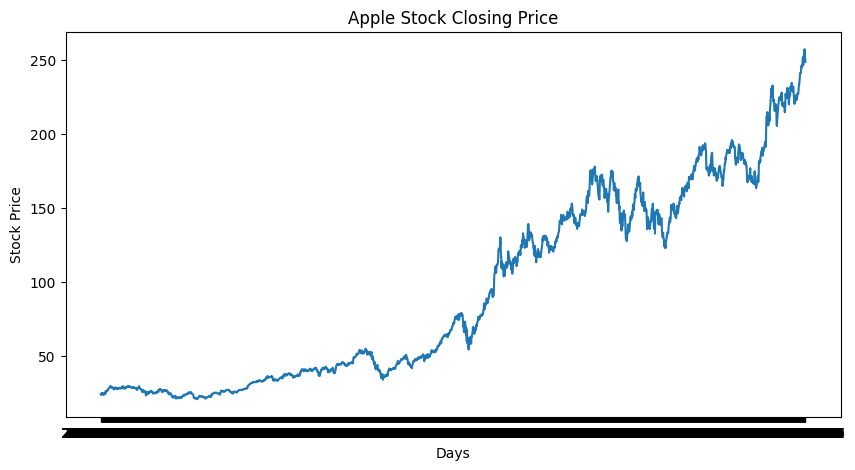

In [5]:
# Display stock closing prices
plt.figure(figsize=(10, 5))

plt.plot(data["Close"])

plt.title("Apple Stock Closing Price")
plt.xlabel("Days")
plt.ylabel("Stock Price")
plt.show()

In [6]:
# Select closing prices
close_prices = data["Close"]

if isinstance(close_prices, pd.DataFrame):
    close_prices = close_prices.iloc[:, 0]

# Split dataset into training and testing data
train_size = int(len(close_prices) * 0.8)

train_data = close_prices.iloc[:train_size].values.reshape(-1, 1)

# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))

scaler.fit(train_data)

scaled_data = scaler.transform(
    close_prices.values.reshape(-1, 1)
)

print("Total Data:", len(scaled_data))
print("Training Data:", train_size)
print("Testing Data:", len(scaled_data) - train_size)

Total Data: 2516
Training Data: 2012
Testing Data: 504


In [7]:
# Create input sequences and output values
X = []
y = []
target_indices = []

for i in range(60, len(scaled_data)):
    X.append(scaled_data[i-60:i, 0])
    y.append(scaled_data[i, 0])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

# Reshape data for RNN
X = X.reshape(X.shape[0], X.shape[1], 1)

# Split sequences into training and testing data
X_train = X[target_indices < train_size]
y_train = y[target_indices < train_size]

X_test = X[target_indices >= train_size]
y_test = y[target_indices >= train_size]

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

X_train Shape: (1952, 60, 1)
X_test Shape: (504, 60, 1)


In [8]:
# Create RNN model
model = Sequential()

model.add(SimpleRNN(50, activation='tanh',
                    input_shape=(60, 1)))

model.add(Dense(1))

# Compile the model
model.compile(optimizer='adam',
              loss='mean_squared_error')

# Display model summary
model.summary()

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=False
)

Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0010 - val_loss: 0.0070
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.1602e-04 - val_loss: 0.0162
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.4299e-04 - val_loss: 0.0042
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.6574e-04 - val_loss: 0.0041
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.0692e-04 - val_loss: 0.0034
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.1674e-04 - val_loss: 0.0028
Epoch 7/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.8433e-04 - val_loss: 0.0024
Epoch 8/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.4261e-04 - val_loss: 0.0021
Epoch 9/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.9894e-04 - val_loss: 0.0020
Epoch 10/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.6229e-04 - val_loss: 0.0020


In [10]:
# Evaluate the model
loss = model.evaluate(X_test, y_test)

print("Test Loss:", loss)

# Predict stock prices
predictions = model.predict(X_test)

# Convert normalized values into original prices
predicted_prices = scaler.inverse_transform(predictions)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

# Display first five predictions
print("Predicted Prices:", predicted_prices[:5].flatten())
print("Actual Prices:", actual_prices[:5].flatten())

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0046     
Test Loss: 0.0046296496875584126
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Predicted Prices: [134.50243 131.60788 131.38287 132.57372 131.024  ]
Actual Prices: [127.24043274 127.55461121 122.7834549  124.04988098 122.73436737]


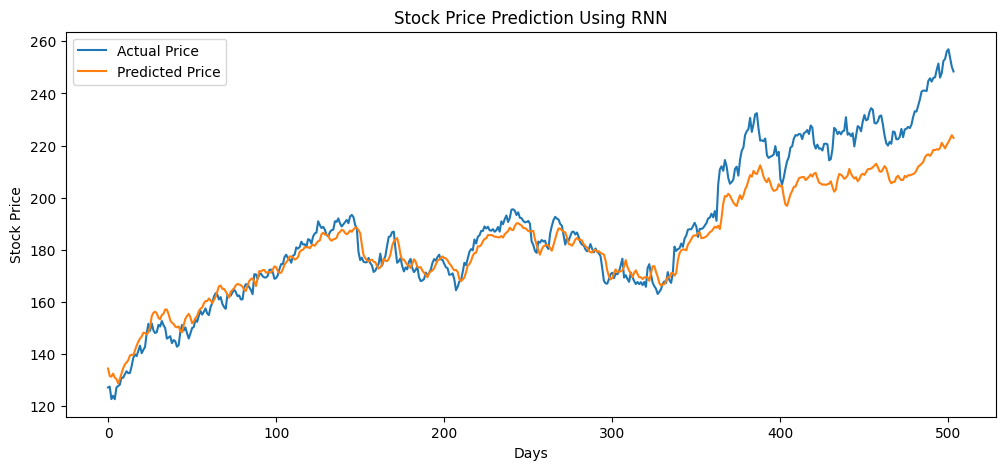

In [11]:
# Plot actual and predicted prices
plt.figure(figsize=(12, 5))

plt.plot(actual_prices, label='Actual Price')
plt.plot(predicted_prices, label='Predicted Price')

plt.title('Stock Price Prediction Using RNN')
plt.xlabel('Days')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

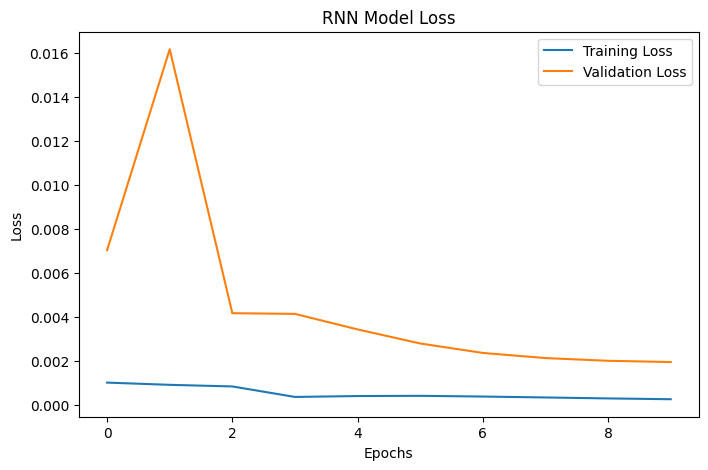

In [12]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('RNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

---
### <b>Practical 2: Text Sentiment Classification Using LSTM/GRU
</b>

**Definition:** Implement a Long Short-Term Memory (LSTM) or Gated Recurrent Unit (GRU) network using Python and TensorFlow/Keras to classify text into positive or negative sentiments. Apply text preprocessing, tokenization, embedding, and sequence modeling to understand how advanced RNN architectures capture contextual and sequential information.


---

In [13]:
from tensorflow import keras
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load IMDB dataset
num_words = 10000

(X_train, y_train), (X_test, y_test) = keras.datasets.imdb.load_data(
    num_words=num_words
)

# Set maximum review length
max_length = 200

# Apply padding
X_train = pad_sequences(
    X_train, maxlen=max_length, padding='post'
)

X_test = pad_sequences(
    X_test, maxlen=max_length, padding='post'
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\keras\src\datasets\npz_utils.py:68: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return RestrictedUnpickler(fp).load()


Training Data: (25000, 200)
Testing Data: (25000, 200)


In [14]:
# Get word index
word_index = keras.datasets.imdb.get_word_index()

# Reverse word index
reverse_word_index = {
    value: key for key, value in word_index.items()
}

# Select random 3 reviews
random_indices = np.random.choice(len(X_train), 3, replace=False)

# Display random reviews
for i in random_indices:

    review = " ".join(
        reverse_word_index.get(word - 3, "?")
        for word in X_train[i]
        if word > 3
    )

    sentiment = "Positive" if y_train[i] == 1 else "Negative"

    print("Review:", review[:300])
    print("Sentiment:", sentiment)
    print()

Review: i really loved it although while reading the reviews it was quite disturbing to me but as an anime art fan i can totally understand this perfect art work even though some of it was against my cultures and believes but hey it's the world of art the beginning of the film is very strong strange and con
Sentiment: Positive

Review: this is hands down the worst movie of all time a combination of goldberg the worst actress person in history and a talking dinosaur ala jar jar add up to a painfully bad movie that was an understatement this movie is unwatchable for the love of god do not watch this movie
Sentiment: Negative

Review: hmm imdb rating of 7 5 good comments okay two of my friends and me we pizza sat down and wanted to see something as cool as or at least something brainless but funny like versus but naked blood sucked it's a complete waste okay the scene with the woman who likes to eat is quite outstanding but that'
Sentiment: Negative



In [15]:
# Create LSTM model
model = keras.Sequential([

    # Embedding layer
    keras.layers.Embedding(
        input_dim=num_words,
        output_dim=128
    ),

    # LSTM layer
    keras.layers.LSTM(64),

    # Dropout layer
    keras.layers.Dropout(0.5),

    # Output layer
    keras.layers.Dense(1, activation='sigmoid')
])

# Display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Compile the LSTM model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the LSTM model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - accuracy: 0.5752 - loss: 0.6804 - val_accuracy: 0.6280 - val_loss: 0.6289
Epoch 2/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.6591 - loss: 0.5940 - val_accuracy: 0.7940 - val_loss: 0.4790
Epoch 3/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - accuracy: 0.7742 - loss: 0.4920 - val_accuracy: 0.8124 - val_loss: 0.4554
Epoch 4/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.6670 - loss: 0.5948 - val_accuracy: 0.6460 - val_loss: 0.6093
Epoch 5/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.6764 - loss: 0.6187 - val_accuracy: 0.7040 - val_loss: 0.5779


In [17]:
# Evaluate the LSTM model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.6908 - loss: 0.5884
Test Loss: 0.5884
Test Accuracy: 69.08 %


In [18]:
# Predict test reviews
predictions = model.predict(X_test[:5])

# Display actual and predicted sentiments
for i in range(5):

    predicted_label = 1 if predictions[i][0] >= 0.5 else 0

    predicted_sentiment = "Positive" if predicted_label == 1 else "Negative"
    actual_sentiment = "Positive" if y_test[i] == 1 else "Negative"

    print("Actual Sentiment:", actual_sentiment)
    print("Predicted Sentiment:", predicted_sentiment)
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
Actual Sentiment: Negative
Predicted Sentiment: Positive

Actual Sentiment: Positive
Predicted Sentiment: Positive

Actual Sentiment: Positive
Predicted Sentiment: Negative

Actual Sentiment: Negative
Predicted Sentiment: Positive

Actual Sentiment: Positive
Predicted Sentiment: Positive



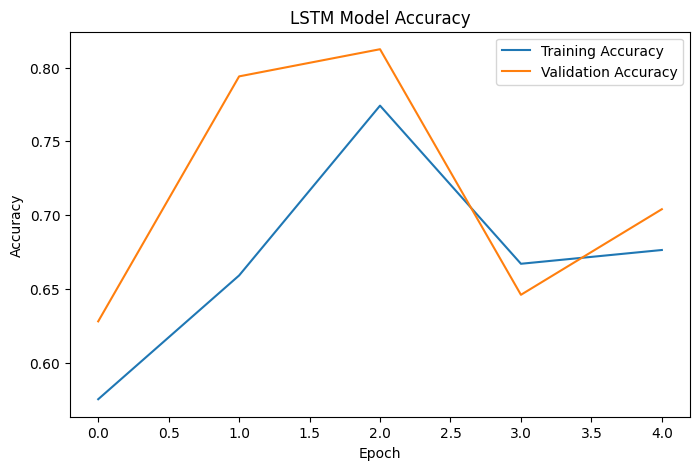

In [19]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('LSTM Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

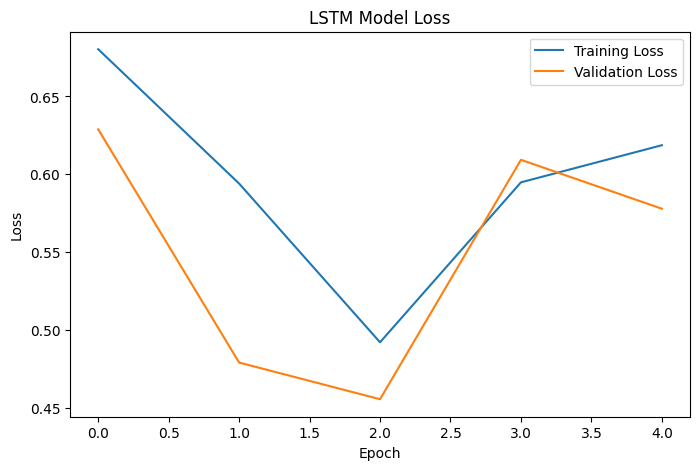

In [20]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('LSTM Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()